> Versión de portafolio. Se conservan las salidas históricas del trabajo académico. Las rutas absolutas de datos, cuando existían, se sustituyeron por nombres locales. Esta versión no se ha ejecutado de nuevo; consulte README y DATOS.md antes de reproducir.


# Tarea M22-CD Javier Bueno Sanchez.

El objetivo de esta actividad es que efectúes un análisis de clasificación mediante Máquinas de soporte vectorial que permita desarrollar un modelo predictivo basado en distintas métricas aplicadas a una base de datos grande.

El objetivo es analizar porqué los empleados deciden irse con la competencia y éste podría ser un desafío serio para un departamento de recursos humanos, el cual se podría abordar mediante modelos predictivos de Machine Learning. Las variables manejadas son:

    satisfaction_level: Nivel de satisfacción. 

    last_evaluation: Puntaje obtenido en la ultima evaluación. 

    average_montly_hours: Promedio de horas trabajadas al mes. 

    time_spend_company: Tiempo del usuario en la compañía. 

    work_accident: Si el empleado ha tenido algún accidente laboral (1 = Sí, 0 = No). 

    promotion_last_5years: Si el empleado ha sido promovido en los últimos 5 años. 

    sales: Departamento donde trabaja. 

    salary: Categoría del salario. 

    left: Variable a predecir y si el empleado dejó o no la empresa (1 = Sí, 0 = No).


Método de Máquinas de soporte vectorial para generar un modelo predictivo. Para dicho fin, pruebe los 4 diferentes tipos de Kernel discutidos en esta lección. En cada caso elabore un mapa de calor para las matrices de confusión así como un reporte de clasificación detallado. Interprete verbalmente sus indicadores. 


¿Cuál resultó ser el modelo predictivo más adecuado? Explique su razonamiento. 

¿Qué resultado pronosticaría para un empleado con los siguientes indicadores?


In [135]:
import pandas as pd
#Biblioteca que permite leer el archivo Excel y manipular la base de datos como tabla.

In [136]:
import numpy as np
#Biblioteca utilizada para operaciones numéricas.
#La usaremos para trabajar con arreglos, valores exponenciales y cálculos matemáticos.

In [137]:
import matplotlib.pyplot as plt
##Biblioteca que permite generar gráficos
#Visualizacion de los datos históricos y el ajuste del modelo.

In [138]:
import seaborn as sns
# Visualizacion de datos.

In [139]:
from sklearn.model_selection import train_test_split
# División de datos.

from sklearn.preprocessing import StandardScaler
# Escalado de variables.

from sklearn.svm import SVC
# Importamos modelo.

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
# Importa las herramientas necesarias para evaluar qué tan bien clasifica el modelo SVM.
# accuracy_score calcula que tanto acierta el modelo.¿Cuántas acertó?
# classification_report genera automáticamente un resumen con varias métricas.
# confusion_matrix construye la matriz de confusion.

In [140]:
import warnings
warnings.filterwarnings("ignore")
# Ignorar advertencias.

In [141]:
import pandas
import sklearn
import matplotlib
import numpy
#Verificamos que todas las librerias quedaron instaladas y su version.

print("Pandas:", pd.__version__)
print("NumPy:", numpy.__version__)
print("Scikit-Learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)

Pandas: 2.3.3
NumPy: 2.3.5
Scikit-Learn: 1.7.2
Matplotlib: 3.10.6


In [142]:
df = pd.read_csv("recursos_humanos.csv")
# Cargamos el archivo

In [143]:
df.head()
# Visualizamos archivo. 

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


## Análisis exploratorio de los datos

In [144]:
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")
# Dimensiones del conjunto de datos.

Filas: 14999
Columnas: 10


In [145]:
df.describe()
# Nos muestra valores.

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


In [146]:
df.isnull().sum()
# Valores nulos por variable.

satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
sales                    0
salary                   0
dtype: int64

In [147]:
df.info()
# Información general del dataset.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   sales                  14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


In [148]:
df["left"].value_counts()
# Distribución de empleados que se fueron vs. permanecieron.

left
0    11428
1     3571
Name: count, dtype: int64

Se verificó la existencia de valores nulos en cada variable del conjunto de datos. No se encontraron registros faltantes, por lo que no fue necesario aplicar técnicas de imputación o eliminación de datos.

## Recodificación de variables categóricas.

In [149]:
df_encoded = pd.get_dummies(df, columns=["sales", "salary"], drop_first=True)
# Las categorías eliminadas no aportan información adicional, ya que pueden inferirse a partir de las restantes variables binarias.

df_encoded.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,1,0,False,False,False,False,False,False,True,False,False,True,False
1,0.80,0.86,5,262,6,0,1,0,False,False,False,False,False,False,True,False,False,False,True
2,0.11,0.88,7,272,4,0,1,0,False,False,False,False,False,False,True,False,False,False,True
3,0.72,0.87,5,223,5,0,1,0,False,False,False,False,False,False,True,False,False,True,False
4,0.37,0.52,2,159,3,0,1,0,False,False,False,False,False,False,True,False,False,True,False


## Separación de variables

In [150]:
X = df_encoded.drop("left", axis=1)
y = df_encoded["left"]

## División entrenamiento / prueba.

In [151]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
# División del conjunto de datos en entrenamiento y prueba.
# test_size = 30% de los datos se guardan para prueba.
# random_state = 42 asegura que el resultado sea reproducible.
# stratify = y mantiene la misma proporción de las clases en los conjuntos de entrenamiento y prueba. 
# De esta forma, ambos representan adecuadamente la distribución original de la base de datos y se evita 
# que una división aleatoria genere muestras poco representativas, lo que podría afectar la evaluación de modelo.

In [152]:
print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)
# Comprobamos funcionamiento del codigo.

(10499, 18)
(4500, 18)
(10499,)
(4500,)


## Escalado de variables.
SVM necesita escalado porque trabaja con distancias y márgenes.

In [153]:
scaler = StandardScaler()
# Crea una herramienta cuya única función será normalizar los datos.

X_train_scaled = scaler.fit_transform(X_train)
# fit Aprende cómo son los datos. Calcula la media y la desviación estándar.
# transform utiliza esas medias y desviaciones para transformar los datos en una escala comparable.
X_test_scaled = scaler.transform(X_test)
# Normalización de las variables.

## Entrenamiento con los 4 kernels requeridos en la actividad.

In [154]:
kernels = ["linear", "poly", "rbf", "sigmoid"]
# linear: Busca una frontera recta que separe ambas clases.
# poly: Permite crear fronteras curvas mediante funciones polinómicas.
# rbf (funcion base radial): Genera fronteras muy flexibles cuando la separación lineal no es suficiente.
# sigmoid: Utiliza una transformación similar a una neurona artificial para intentar separar las clases.

In [155]:
resultados = []

for kernel in kernels:
    model = SVC(kernel=kernel, random_state=42)
    model.fit(X_train_scaled, y_train)
    
    y_pred = model.predict(X_test_scaled)
    
    print(f"Kernel: {kernel}")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))

    report = classification_report(y_test, y_pred, output_dict=True)

    resultados.append({"Kernel": kernel, "Accuracy": accuracy_score(y_test, y_pred), "Precision": report["1"]["precision"],
    "Recall": report["1"]["recall"], "F1-score": report["1"]["f1-score"]})
# Utilizamos un ciclo for para ejecutar los 4 modelos, donde recibimos los diferentes datos que utilizaremos 
# para concluir cual modelo es el mas adecuado.

tabla_resultados = pd.DataFrame(resultados)

tabla_resultados

Kernel: linear
Accuracy: 0.7742222222222223
              precision    recall  f1-score   support

           0       0.80      0.93      0.86      3429
           1       0.55      0.26      0.36      1071

    accuracy                           0.77      4500
   macro avg       0.68      0.60      0.61      4500
weighted avg       0.74      0.77      0.74      4500

Kernel: poly
Accuracy: 0.9382222222222222
              precision    recall  f1-score   support

           0       0.95      0.97      0.96      3429
           1       0.90      0.83      0.87      1071

    accuracy                           0.94      4500
   macro avg       0.92      0.90      0.91      4500
weighted avg       0.94      0.94      0.94      4500

Kernel: rbf
Accuracy: 0.9526666666666667
              precision    recall  f1-score   support

           0       0.97      0.97      0.97      3429
           1       0.90      0.90      0.90      1071

    accuracy                           0.95      4500
 

,Kernel,Accuracy,Precision,Recall,F1-score
0,linear,0.774222,0.554028,0.263305,0.356962
1,poly,0.938222,0.900101,0.832866,0.865179
2,rbf,0.952667,0.901685,0.899160,0.900421
3,sigmoid,0.635111,0.213641,0.198880,0.205996


## Interpretacion de cada kernel.

### Kernel Linear

El kernel lineal obtuvo un Accuracy del 77.4%. Aunque clasificó correctamente a la mayoría de los empleados que permanecen en la empresa, presentó un Recall de únicamente 0.26 para la clase "Abandona". Esto significa que logró identificar solo el 26% de los empleados que realmente dejaron la organización, por lo que no resulta adecuado para este problema.

### Kernel Polynomial

El kernel polinómico mostró una mejora considerable respecto al modelo lineal. Alcanzó un Accuracy del 93.8% y un F1-score de 0.87 para la clase "Abandona", demostrando una buena capacidad para identificar empleados con riesgo de salida sin incrementar significativamente los errores de clasificación.

### Kernel RBF

El kernel RBF obtuvo el mejor desempeño entre los cuatro modelos evaluados. Alcanzó un Accuracy del 95.3%, además de valores de Precision, Recall y F1-score cercanos al 90% para la clase "Abandona". Esto indica un equilibrio adecuado entre detectar correctamente a los empleados que abandonan la empresa y minimizar los errores de clasificación.

### Kernel Sigmoid

El kernel sigmoid presentó el rendimiento más bajo del estudio. Su Accuracy fue del 63.5% y únicamente identificó el 20% de los empleados que realmente abandonaron la empresa. Debido a este bajo desempeño, no se considera una alternativa adecuada para este conjunto de datos.

## Matriz de confusión con mapa de calor.

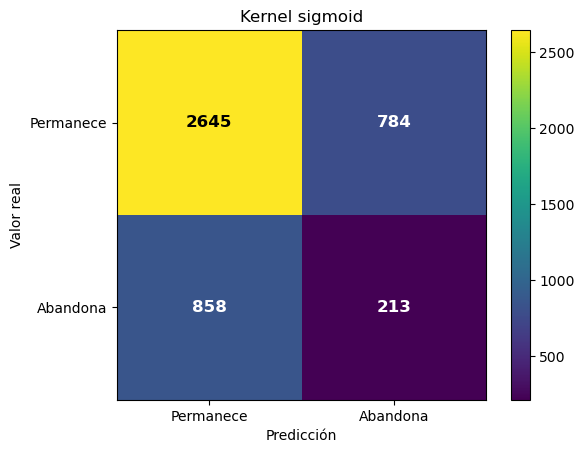

In [156]:
fig, ax = plt.subplots()
# Creamos la figura donde se mostrará la matriz de confusión.

cm = confusion_matrix(y_test, y_pred)
im = ax.imshow(cm)
# Calculamos la matriz utilizando las predicciones del modelo.

ax.set_title(f"Kernel {kernel}")
ax.set_xlabel("Predicción")
ax.set_ylabel("Valor real")
# Configuramos las etiquetas de las clases en ambos ejes.

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Permanece", "Abandona"])
ax.set_yticklabels(["Permanece", "Abandona"])
# Escribimos el valor correspondiente en cada celda.

threshold = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        color = "white" if cm[i, j] < threshold else "black"

        ax.text(j, i, cm[i, j], ha="center", va="center", color=color, fontsize=12, fontweight="bold")
# Creamos una funcion que clasifique la matriz de confusion por medio de 0 (permanece) y 1 (abandona) 
# y le damos ubicacion en el mapa de calor. Le indicamos con color, fontsize y fontweight que adapte
# el texto dentro de los cuadros del mapa para una mejor lectura.

plt.colorbar(im)
# Añadimos la barra de colores para facilitar la interpretación.

plt.show()

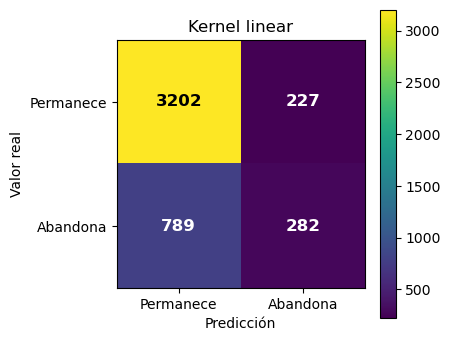

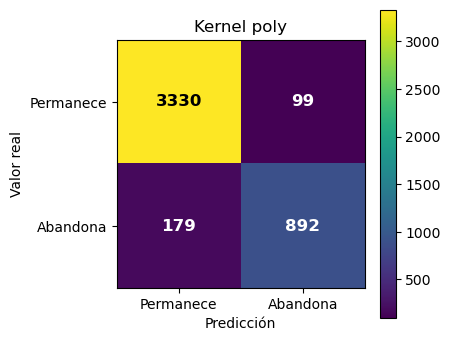

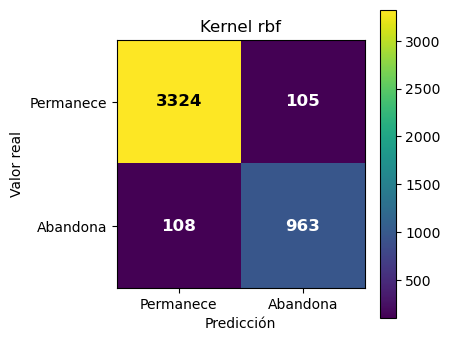

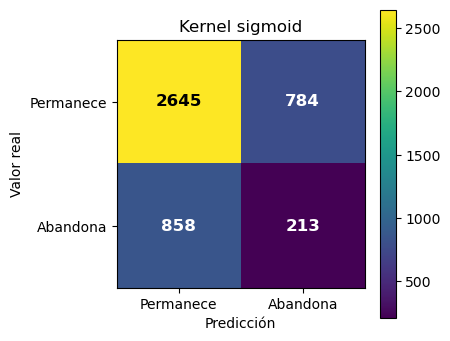

In [157]:
for kernel in kernels:

    model = SVC(kernel=kernel, random_state=42)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    cm = confusion_matrix(y_test, y_pred)

    fig, ax = plt.subplots(figsize=(4,4))

    im = ax.imshow(cm)

    ax.set_title(f"Kernel {kernel}")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")

    ax.set_xticks([0,1])
    ax.set_yticks([0,1])

    ax.set_xticklabels(["Permanece","Abandona"])
    ax.set_yticklabels(["Permanece","Abandona"])

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
             color = "white" if cm[i, j] < threshold else "black"
             ax.text(j, i, cm[i, j], ha="center", va="center", color=color, fontsize=12, fontweight="bold")
# Creamos una funcion que clasifique la matriz de confusion por medio de 0 (permanece) y 1 (abandona) 
# y le damos ubicacion en el mapa de calor. Le indicamos con color, fontsize y fontweight que adapte
# el texto dentro de los cuadros del mapa para una mejor lectura.


    plt.colorbar(im)
    plt.show()

## ¿Cuál resultó ser el modelo predictivo más adecuado?

## Modelo seleccionado: Kernel RBF.

Después de comparar los cuatro kernels mediante Accuracy, Precision, Recall y F1-score, el modelo basado en el kernel RBF (Radial Basis Function) resultó ser el más adecuado para este problema de clasificación.

Razones:
1. Obtuvo el mayor Accuracy (95.3%);
2. Presentó el mejor equilibrio entre Precision y Recall;
3. Alcanzó un F1-score de 0.90 para la clase "Abandona";
4. Identificó correctamente la mayoría de los empleados que realmente dejaron la empresa, reduciendo tanto falsos positivos como falsos negativos.

Resumiendo, el kernel RBF ofrece la mejor capacidad predictiva para apoyar al departamento de Recursos Humanos en la identificación temprana de empleados con riesgo de abandono.

## Conclusión final

El análisis demuestra que la elección del kernel influye directamente en la capacidad predictiva del modelo. Aunque todos los modelos utilizan Máquinas de Soporte Vectorial, cada kernel construye fronteras de decisión diferentes. En este caso, el kernel RBF fue el que mejor logró representar el comportamiento de los datos, permitiendo identificar con mayor precisión a los empleados con riesgo de abandonar la empresa. Esto demuestra la importancia de comparar distintos modelos antes de implementar una solución basada en Machine Learning.

## ¿Qué resultado pronosticaría para un empleado con los siguientes indicadores?

"satisfaction_level": [0.50],
"last_evaluation": [0.75],
"number_project": [4],
"average_montly_hours": [200],
"time_spend_company": [4],
"Work_accident": [0],
"promotion_last_5years": [0],
"sales": ["sales"],
"salary": ["medium"]

In [158]:
nuevo_empleado = pd.DataFrame({"satisfaction_level": [0.50],"last_evaluation": [0.75],
    "number_project": [4],"average_montly_hours": [200],"time_spend_company": [4],"Work_accident": [0],
    "promotion_last_5years": [0],"sales": ["sales"],"salary": ["medium"]})
# Creamos un dataframe nuevo con los datos referidos del nuevo empleado para poder aplicarle el modelo.

In [159]:
nuevo_empleado = pd.get_dummies(nuevo_empleado,columns=["sales", "salary"])
# Las categorías eliminadas no aportan información adicional, ya que pueden inferirse a partir de las restantes variables binarias.


In [160]:
nuevo_empleado = nuevo_empleado.reindex(columns=X.columns,fill_value=0)
# Entrenamos el modelo con 18 variables, debemos agregar las faltantes, donde X.columns nos entrega
# con la que entrenamos la SVM.

In [161]:
nuevo_empleado_scaled = scaler.transform(nuevo_empleado)
# Recordemos que debemos enseñarle con la misma escala que apredió en el entrenamiento.                                        )

In [162]:
modelo_rbf = SVC(kernel="rbf", random_state=42)
# Solo utilizaremos el modelo RBF.
modelo_rbf.fit(X_train_scaled, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [163]:
prediccion = modelo_rbf.predict(nuevo_empleado_scaled)

print(prediccion)

if prediccion[0] == 0:
    print("Predicción: El empleado permanecerá en la empresa.")
else:
    print("Predicción: El empleado abandonará la empresa.")

[0]
Predicción: El empleado permanecerá en la empresa.


### El modelo SVM con kernel RBF predice que este empleado permanecerá en la empresa (clase 0). Aunque inicialmente la hipótesis planteaba que el empleado tenía "un pie dentro y otro fuera", el modelo encontró patrones más consistentes con los empleados que permanecen en la organización. Este resultado pone de manifiesto la importancia de complementar la intuición con modelos predictivos entrenados sobre datos históricos.